# 소비 인텔리전스 1단계 · 탐색적 데이터 분석(EDA)

**목적**: 가계부 거래 데이터를 SQL(DuckDB)로 집계하고, 소비 패턴 · 반복 결제 · 이상 지출 규칙을 확인한다.

> ⚠️ 이 노트북의 데이터는 **합성 데이터**(`make_synthetic.py`로 만든 가상의 세 사람, 13개월)다.
> 숫자는 규칙이 제대로 동작하는지 확인하려고 지어낸 값이며 **실제 사람들의 소비 통계가 아니다**.
> 실제 가계부로 돌리려면 앱에서 내보낸 CSV로 `run_sql.py --tx 파일.csv`를 실행한다.

In [1]:
import sys, duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path("analysis")
sys.path.insert(0, str(ROOT / "python"))
from run_sql import connect
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
D = ROOT / "data"
as_of = (D / "as_of.csv").read_text(encoding="utf-8").splitlines()[1]
con = connect(D / "synthetic_tx.csv", D / "synthetic_budgets.csv", D / "synthetic_fixed.csv", as_of)
q = lambda name: con.execute((ROOT / "sql" / f"{name}.sql").read_text(encoding="utf-8")).df()
LABEL = {"u_student": "대학생", "u_junior": "사회초년생", "u_saver": "절약형"}
print("기준일", as_of)

기준일 2026-11-12


## 1. 데이터 한눈에 보기
거래가 어떤 종류(지출·수입·환불·내부이체)로 나뉘는지, 사람마다 몇 건인지 본다. 분류 기준은 `00_schema.sql`의 `tx_class` 보기에 한 번만 정의했다.

In [2]:
con.execute("""
SELECT user_id, kind, count(*) AS n, sum(amount) AS amount, min(date) AS first, max(date) AS last
FROM tx_class GROUP BY ALL ORDER BY user_id, kind""").df()

,user_id,kind,n,amount,first,last
0,u_junior,income,12,33600000.0,2025-11-25,2026-10-25
1,u_junior,spend,1026,16435100.0,2025-11-01,2026-11-12
2,u_junior,transfer,12,6000000.0,2025-11-26,2026-10-26
3,u_saver,income,13,29900000.0,2025-11-10,2026-11-10
4,u_saver,spend,610,5645400.0,2025-11-01,2026-11-12
5,u_student,income,12,10800000.0,2025-11-25,2026-10-25
6,u_student,refund,2,27200.0,2026-02-05,2026-08-01
7,u_student,spend,888,7831300.0,2025-11-01,2026-11-12


## 2. 월별 소비 추세 (`01_monthly_summary.sql`)
'쓴 돈' = 지출 − 환불(앱과 같은 기준). 마지막 달은 기준일까지라 덜 찼다.

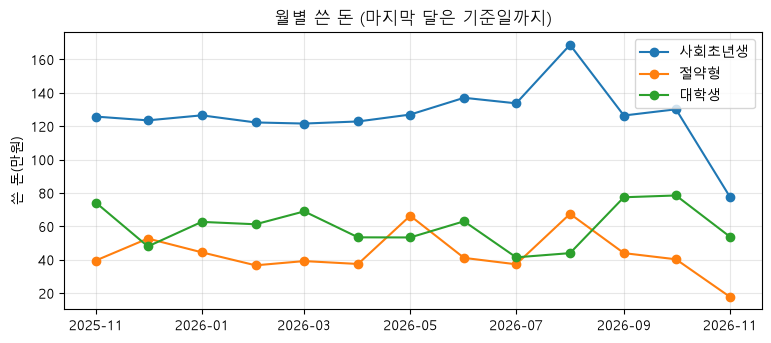

,user_id,month,spend,income,fixed_spend,variable_spend,n_spend,prev_spend,spend_change_pct
33,u_student,2026-06-01,630600.0,900000.0,55000.0,575600.0,70,533750.0,18.1
34,u_student,2026-07-01,414550.0,900000.0,55000.0,359550.0,61,630600.0,-34.3
35,u_student,2026-08-01,439850.0,900000.0,55000.0,399550.0,68,414550.0,6.1
36,u_student,2026-09-01,774550.0,900000.0,55000.0,719550.0,86,439850.0,76.1
37,u_student,2026-10-01,785250.0,900000.0,55000.0,730250.0,79,774550.0,1.4
38,u_student,2026-11-01,538500.0,0.0,55000.0,483500.0,38,785250.0,-31.4


In [3]:
m = q("01_monthly_summary")
fig, ax = plt.subplots(figsize=(9, 3.6))
for u, g in m.groupby("user_id"):
    ax.plot(g["month"], g["spend"] / 1e4, marker="o", label=LABEL[u])
ax.set_ylabel("쓴 돈(만원)"); ax.set_title("월별 쓴 돈 (마지막 달은 기준일까지)"); ax.legend(); ax.grid(alpha=.3)
plt.show()
m.tail(6)

## 3. 분류별 추세와 증감률 (`02_category_trend.sql`)
대학생의 카페·간식 지출이 9월부터 늘어나도록 합성 데이터를 만들었다. 3개월 이동평균(ma3)과 지난달 대비 증감률로 그 변화가 보이는지 확인한다.

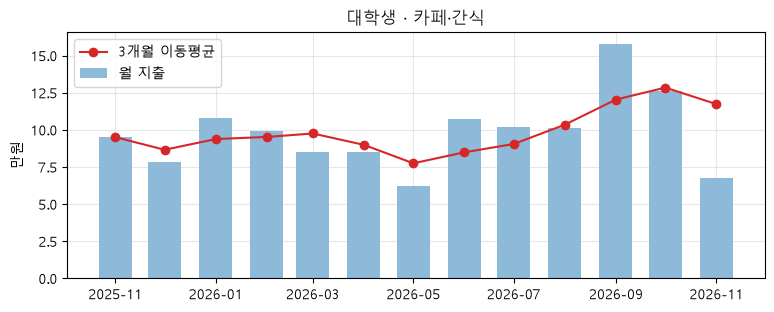

,month,spend,share_pct,change_pct,ma3
280,2026-06-01,107300.0,17.0,72.5,84900.0
281,2026-07-01,102000.0,24.6,-4.9,90500.0
282,2026-08-01,101200.0,22.3,-0.8,103500.0
283,2026-09-01,158000.0,20.4,56.1,120400.0
284,2026-10-01,126200.0,16.1,-20.1,128467.0
285,2026-11-01,67800.0,12.6,-46.3,117333.0


In [4]:
c = q("02_category_trend")
s = c[(c.user_id == "u_student") & (c.cat == "카페·간식")]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(s["month"], s["spend"] / 1e4, width=20, alpha=.5, label="월 지출")
ax.plot(s["month"], s["ma3"] / 1e4, color="C3", marker="o", label="3개월 이동평균")
ax.set_ylabel("만원"); ax.set_title("대학생 · 카페·간식"); ax.legend(); ax.grid(alpha=.3)
plt.show()
s[["month", "spend", "share_pct", "change_pct", "ma3"]].tail(6)

## 4. 요일별 소비 성향 (`03_weekday.sql`)
지출이 없는 날도 0원으로 세야 평균이 부풀지 않아서, 날짜 달력을 만들어 LEFT JOIN 했다(최근 12주, 고정비 제외).

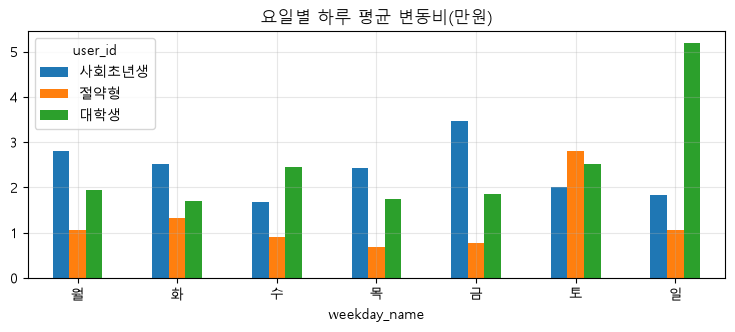

In [5]:
w = q("03_weekday")
p = w.pivot(index="weekday_name", columns="user_id", values="avg_daily_spend").reindex(list("월화수목금토일"))
p.rename(columns=LABEL).div(1e4).plot.bar(figsize=(9, 3.2), rot=0, title="요일별 하루 평균 변동비(만원)").grid(alpha=.3)
plt.show()

## 5. 고정비 · 변동비 (`04_fixed_variable.sql`)

In [6]:
f = q("04_fixed_variable"); f[f.month == f.month.max()]

,user_id,month,fixed_spend,variable_spend,fixed_share_pct,fixed_items
12,u_junior,2026-11-01,520000.0,257650.0,66.9,"월세, 통신비"
25,u_saver,2026-11-01,33000.0,145250.0,18.5,통신비
38,u_student,2026-11-01,55000.0,483500.0,10.2,통신비


## 6. 반복 결제 탐지 (`05_recurring.sql`)
고정으로 등록하지 않은 구독(OTT·음악·헬스장)도 잡히는지, 매일 가는 카페는 빠지는지 본다.

In [7]:
q("05_recurring")

,user_id,merchant,cat,n,typical_amount,cycle,median_gap,gap_sd,last_date,next_expected,is_fixed
0,u_junior,월세,주거·통신,6,450000.0,매달,31.0,0.49,2026-11-01,2026-12-02,True
1,u_junior,통신비,주거·통신,6,70000.0,매달,31.0,0.49,2026-11-12,2026-12-13,True
2,u_junior,헬스장,의료·건강,5,59000.0,매달,30.5,0.50,2026-10-15,2026-11-15,False
3,u_junior,음악 구독,구독,6,10900.0,매달,31.0,0.49,2026-11-07,2026-12-08,False
4,u_saver,관리비,주거·통신,6,120000.0,매달,31.0,0.49,2026-10-20,2026-11-20,True
5,u_saver,통신비,주거·통신,6,33000.0,매달,31.0,0.49,2026-11-05,2026-12-06,True
6,u_student,통신비,주거·통신,6,55000.0,매달,31.0,0.49,2026-11-10,2026-12-11,True
7,u_student,OTT 구독,구독,6,13900.0,매달,31.0,0.49,2026-11-03,2026-12-04,False


## 7. 이상 지출 규칙 비교 (`06_anomaly.sql`)

합성 데이터에 **일부러 넣은 이상 지출 5건**(`anomalies_truth.csv`)을 정답으로 두고 두 규칙을 비교한다.
- **규칙 A (처음 안)**: 같은 분류 최근 90일 중앙값 + 3.5 × 1.4826 × MAD, 지난 기록 5번 이상
- **규칙 B (채택)**: 같은 분류 최근 90일 P95 × 2, 3만원 이상, 지난 기록 3번 이상

정밀도(precision) = 잡은 것 중 정답 비율, 재현율(recall) = 정답 중 잡은 비율.

In [8]:
truth = pd.read_csv(D / "anomalies_truth.csv")
rule_a = con.execute("""
WITH h AS (SELECT s.*, count(*) OVER w n, median(amount) OVER w med, mad(amount) OVER w mad
           FROM tx_class s WHERE kind = 'spend'
           WINDOW w AS (PARTITION BY user_id, cat ORDER BY date RANGE BETWEEN INTERVAL 90 DAY PRECEDING AND INTERVAL 1 DAY PRECEDING))
SELECT id FROM h WHERE n >= 5 AND amount >= 10000
  AND CASE WHEN mad > 0 THEN amount > med + 3.5 * 1.4826 * mad ELSE amount > med * 3 END""").df()
rule_b = q("06_anomaly")
def score(name, ids):
    hit = len(set(ids) & set(truth.id))
    return {"규칙": name, "잡은 수": len(ids), "맞힘": hit, "정밀도": round(hit / max(len(ids), 1), 2), "재현율": round(hit / len(truth), 2)}
pd.DataFrame([score("A 중앙값+MAD", rule_a.id), score("B P95×2 (채택)", rule_b.id)])

,규칙,잡은 수,맞힘,정밀도,재현율
0,A 중앙값+MAD,140,4,0.03,0.8
1,B P95×2 (채택),7,4,0.57,0.8


In [9]:
rule_b.assign(정답=rule_b.id.isin(truth.id))

,user_id,id,date,merchant,cat,amount,n_prior,prior_median,prior_p95,times_usual,정답
0,u_junior,t01265,2026-03-13,식당,식비,52500,90,10250.0,26155.0,5.1,False
1,u_junior,t01362,2026-04-17,식당,식비,53600,85,9900.0,26180.0,5.4,False
2,u_junior,t02573,2026-06-14,식당,식비,210000,90,9800.0,33435.0,21.4,True
3,u_junior,t02574,2026-11-02,카페,카페·간식,64000,60,5250.0,6805.0,12.2,True
4,u_saver,t02258,2026-05-10,배달앱,식비,30700,35,8000.0,13010.0,3.8,False
5,u_student,t02571,2026-10-18,식당,식비,96000,59,9100.0,25200.0,10.5,True
6,u_student,t02572,2026-11-08,온라인쇼핑,쇼핑,189000,9,41700.0,87240.0,4.5,True


**해석**
- 규칙 A는 식비 안에 '구내식당 1만원'과 '배달·식당 2~5만원'이 섞인 **두 봉우리 분포** 때문에 평범한 배달까지 잡아 정밀도가 낮다.
- 규칙 B는 평소의 '윗부분'(P95)과 비교해 이 섞임에 덜 흔들린다. 다만 지난 기록이 적은 분류(절약형의 쇼핑)는 기준을 세울 수 없어 놓친다(**콜드 스타트** 한계).
- 정답 밖에서 잡힌 '식당 5만원'은 실제로도 평소보다 큰 지출이라, 사용자에게는 '평소보다 큰 지출' 정도로 부드럽게 알린다.
- 정답표가 합성 데이터에서 온 것이라 이 숫자는 **규칙이 의도대로 동작하는지 확인하는 용도**이고, 실제 성능 주장이 아니다.

## 8. 예산 대비 (`07_budget.sql`) · 이번 달 현황 (`08_month_to_date.sql`)

In [10]:
q("07_budget")

,user_id,cat,budget,spent,remaining,used_pct,days_left,status
0,u_junior,카페·간식,100000,94100.0,5900.0,94.1,19,주의
1,u_junior,교통,80000,29450.0,50550.0,36.8,19,여유
2,u_junior,식비,450000,123200.0,326800.0,27.4,19,여유
3,u_junior,쇼핑,250000,0.0,250000.0,0.0,19,여유
4,u_junior,문화·여가,150000,0.0,150000.0,0.0,19,여유
5,u_junior,여행,300000,0.0,300000.0,0.0,19,여유
6,u_saver,카페·간식,30000,25200.0,4800.0,84.0,19,주의
7,u_saver,교통,70000,26350.0,43650.0,37.6,19,여유
8,u_saver,쇼핑,80000,29500.0,50500.0,36.9,19,여유
9,u_saver,식비,250000,64200.0,185800.0,25.7,19,여유


In [11]:
q("08_month_to_date")

,user_id,cat,cur_spend,prev_spend,cur_fixed
0,u_junior,합계,777650.0,845950.0,520000.0
1,u_junior,주거·통신,520000.0,520000.0,520000.0
2,u_junior,식비,123200.0,156700.0,0.0
3,u_junior,카페·간식,94100.0,50300.0,0.0
4,u_junior,교통,29450.0,26350.0,0.0
5,u_junior,구독,10900.0,10900.0,0.0
6,u_junior,쇼핑,0.0,81700.0,0.0
7,u_saver,합계,178250.0,134300.0,33000.0
8,u_saver,식비,64200.0,54600.0,0.0
9,u_saver,주거·통신,33000.0,33000.0,33000.0


## 9. 한계
- 합성 데이터는 규칙을 만든 사람이 만든 데이터라, 규칙이 데이터에 맞춰질 위험이 있다 → 실제 내보낸 데이터로 다시 확인해야 한다.
- 분류는 사용자가 고른 값이라 틀릴 수 있다(예: 월급을 다른 분류로 기록). 앱에서는 '들어온 돈'을 고르면 '급여·수입'이 자동 선택되게 해 두었다.
- 반복 결제는 180일, 이상 지출은 90일 기록이 있어야 의미가 있다. 기록이 부족하면 앱은 숫자 대신 안내 문구를 보여 준다.